**5. Implement Agglomerative hierarchical clustering algorithm using appropriate dataset.**

In [1]:
!pip install pandas matplotlib scikit-learn scipy

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ------------- -------------------------- 3.1/9.5 MB 17.7 MB/s eta 0:00:01
   -------------------------- ------------- 6.3/9.5 MB 15.8 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 15.2 MB/s  0:00:00
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 15.8 MB/s  0:00:00
   ---------------------------------------- 0.0/7.3 MB ? eta -:--:--
   --------------------- ------------------ 3.9/7.3 MB 19.2 MB/s eta 0:00:01
   ------------------------------- -------- 5.8/7.3 MB 14.4 MB/s eta 0:00:01
   ---------------------------------------- 7.3/7.3 MB 14.0 MB/s  0:00:00

   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ----------------------

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram,linkage

In [4]:
iris=load_iris()
df=pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


In [5]:
x=df
x.shape

(150, 4)

In [6]:
scaler=StandardScaler()

x_scale=scaler.fit_transform(x)
x_scale[:5]

array([[-0.90068117,  1.01900435, -1.34022653, -1.3154443 ],
       [-1.14301691, -0.13197948, -1.34022653, -1.3154443 ],
       [-1.38535265,  0.32841405, -1.39706395, -1.3154443 ],
       [-1.50652052,  0.09821729, -1.2833891 , -1.3154443 ],
       [-1.02184904,  1.24920112, -1.34022653, -1.3154443 ]])

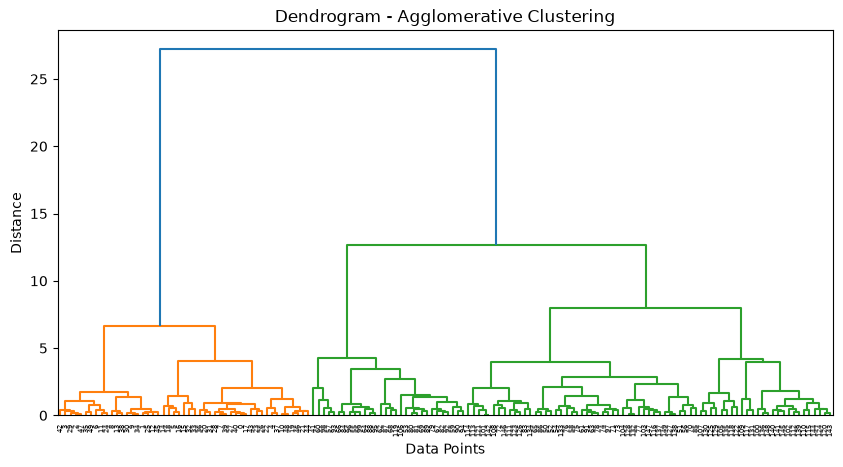

In [8]:
linked=linkage(x_scale,method="ward")
plt.figure(figsize=(10,5))

dendrogram(linked)
plt.title("Dendrogram - Agglomerative Clustering")
plt.xlabel("Data Points")
plt.ylabel("Distance")

plt.show()

In [9]:
model=AgglomerativeClustering(
    n_clusters=3,
    linkage="ward",

)
clusters=model.fit_predict(x_scale)
df["Cluster"]=clusters
df


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Cluster
0,5.1,3.5,1.4,0.2,1
1,4.9,3.0,1.4,0.2,1
2,4.7,3.2,1.3,0.2,1
3,4.6,3.1,1.5,0.2,1
4,5.0,3.6,1.4,0.2,1
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,0
146,6.3,2.5,5.0,1.9,0
147,6.5,3.0,5.2,2.0,0
148,6.2,3.4,5.4,2.3,0


In [10]:
df['Cluster'].value_counts().sort_index()

Cluster
0    71
1    49
2    30
Name: count, dtype: int64

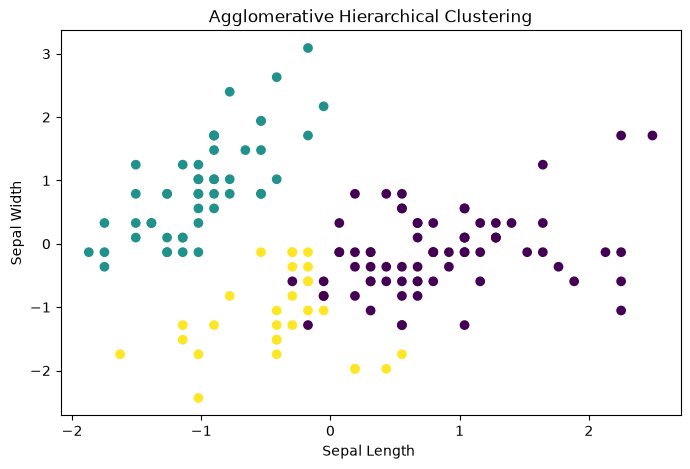

In [11]:
plt.figure(figsize=(8,5))
plt.scatter(
    x_scale[:,0],
    x_scale[:,1],
    c=clusters,
    cmap='viridis'
)
plt.title("Agglomerative Hierarchical Clustering")
plt.xlabel("Sepal Length ")
plt.ylabel("Sepal Width")
plt.show()